# Load dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [6]:
penguins = pd.read_csv("penguins.csv")


In [8]:
penguins = penguins.dropna()

In [10]:
X = penguins[['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']].values


In [12]:
species = penguins['species'].astype('category')
y = species.cat.codes.values.reshape(-1,1)   
num_classes = len(species.cat.categories)

# Train or test split

In [30]:
idx = np.arange(len(X))
np.random.seed(42)
np.random.shuffle(idx)

X, y = X[idx], y[idx]

In [32]:
split = int(0.8*len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [34]:
X_mean, X_std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - X_mean) / (X_std + 1e-8)
X_test = (X_test - X_mean) / (X_std + 1e-8)


#  Softmax Logistic Regression with L2 regularization


In [ ]:
def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / exp_z.sum(axis=1, keepdims=True)

def train_multiclass_logreg(X, y, num_classes, lr=0.1, epochs=800, reg_lambda=0.05):
    N, d = X.shape
    W = np.zeros((d, num_classes))
    b = np.zeros((1, num_classes))
    Y = np.zeros((N, num_classes))
    Y[np.arange(N), y.flatten()] = 1
    
    for ep in range(epochs):
        scores = X @ W + b
        probs = softmax(scores)
        
        error = probs - Y
        grad_W = (X.T @ error) / N + reg_lambda * W
        grad_b = np.mean(error, axis=0, keepdims=True)
        
        W -= lr * grad_W
        b -= lr * grad_b
        
        if ep % 100 == 0:
            loss = -np.mean(np.sum(Y * np.log(probs+1e-8), axis=1)) + (reg_lambda/2)*np.sum(W*W)
            print(f"Epoch {ep}: Loss={loss:.4f}")
    return W, b

In [43]:
def predict_multiclass(X, W, b):
    probs = softmax(X @ W + b)
    return np.argmax(probs, axis=1)

#  Train and Evaluate

In [ ]:
W, b = train_multiclass_logreg(X_train, y_train, num_classes, lr=0.1, epochs=800, reg_lambda=0.05)
y_pred = predict_multiclass(X_test, W, b)
y_true = y_test.flatten().astype(int)
y_pred = y_pred.flatten().astype(int)
accuracy = np.mean(y_pred == y_true)
print("Penguin Dataset Accuracy:", accuracy)
print("First 10 Predictions:", y_pred[:10])
print("First 10 Actual:", y_true[:10])


Epoch 0: Loss=1.6096
Epoch 100: Loss=0.5825
Epoch 200: Loss=0.5363
Epoch 300: Loss=0.5208
Epoch 400: Loss=0.5129
Epoch 500: Loss=0.5082
Epoch 600: Loss=0.5051
Epoch 700: Loss=0.5029
Penguin Dataset Accuracy: 0.9180327868852459
First 10 Predictions: [1 2 1 2 2 0 2 2 2 2]
First 10 Actual: [1 2 1 2 2 0 2 2 2 2]


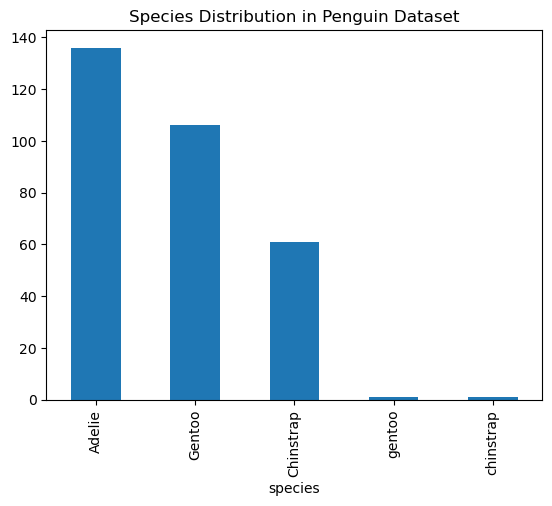

In [48]:
penguins['species'].value_counts().plot(kind='bar')
plt.title("Species Distribution in Penguin Dataset")
plt.show()

In [52]:
with open("a1_bonus_improved_odrabira_pranayl.pkl", "wb") as f:
    pickle.dump((W, b), f)

In [ ]:
#REFERENCES:
https://pandas.pydata.org
https://numpy.org
https://elcaiseri.medium.com/building-a-simple-logistic-regression-model-from-scratch-with-numpy-c8cf2439d059
https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/
https://medium.com/%40arjunprakash027/building-softmax-regression-from-scratch-a-hands-on-guide-with-python-code-5615166c9d4c

| Team Member | Assignment part | Contribution |
|----------|----------|----------|
| Odra Bira | bonus improved | 40% |
| Pranay Lachuluri | bonus improved | 60% |

